# Telecom Customer Churn Prediction
## Random Forest & XGBoost — pipeline de Machine Learning

### Objectif
Prédire la résiliation (`Churn`) des clients d'une entreprise de télécommunications afin d'identifier les profils à risque et d'appuyer les actions de fidélisation.

### Périmètre
Ce notebook couvre la partie Machine Learning du projet Telecom Churn Analytics. Il utilise le CSV source et fonctionne indépendamment de la chaîne BI SQL Server / SSIS / SSAS / Power BI. La BI décrit les tendances observées ; le ML estime la probabilité de résiliation.

### Étapes
1. Charger et explorer les données.
2. Nettoyer les données et vérifier les valeurs manquantes.
3. Définir la cible et séparer les données en entraînement et test.
4. Prétraiter les variables dans un pipeline.
5. Optimiser Random Forest et XGBoost.
6. Choisir un seuil sans utiliser le jeu de test.
7. Évaluer les modèles sur le jeu de test.
8. Interpréter les métriques et enregistrer les résultats.

**Reproductibilité :** une graine aléatoire fixe est utilisée. Les scores peuvent varier selon les versions des bibliothèques et l'environnement. Exécuter toutes les cellules dans l'ordre avant de publier les résultats.

## 1. Imports et configuration

Les bibliothèques utilisées couvrent la manipulation des données (`pandas`, `numpy`), les visualisations (`matplotlib`, `seaborn`), les pipelines et métriques (`scikit-learn`), l'entraînement de XGBoost et la sauvegarde des modèles (`joblib`).

Si XGBoost n'est pas installé, exécuter `%pip install xgboost`, puis redémarrer le noyau si nécessaire.

In [2]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV, cross_val_predict
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, fbeta_score,
    roc_auc_score, average_precision_score, classification_report,
    confusion_matrix, RocCurveDisplay, PrecisionRecallDisplay, precision_recall_curve
)
RANDOM_STATE = 42
pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")

## 2. Charger le CSV brut

Le notebook utilise le jeu de données **Telco Customer Churn**, généralement nommé `WA_Fn-UseC_-Telco-Customer-Churn.csv`. Si le fichier n'est pas inclus dans le dépôt, le télécharger depuis la source indiquée ci-dessous et placer le CSV à côté du notebook, ou adapter `DATA_PATH`.

La première vérification porte sur le nombre de lignes, le nombre de colonnes et un aperçu des données.

**Source du dataset :** IBM Telco Customer Churn, disponible sur Kaggle : https://www.kaggle.com/datasets/blastchar/telco-customer-churn. Vérifier les conditions de redistribution sur la page source.

In [3]:
# Ce chemin fonctionne sur Kaggle si le dataset est ajouté au notebook.
# En local, place le CSV à côté du notebook ou modifie DATA_PATH.
DATA_PATH = Path("/kaggle/input/datasets/blastchar/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv")
if not DATA_PATH.exists():
    candidates = list(Path(".").glob("*.csv"))
    if len(candidates) == 1:
        DATA_PATH = candidates[0]
        print("CSV détecté :", DATA_PATH)
    else:
        raise FileNotFoundError(
            "CSV introuvable. Place le fichier Telco Customer Churn à côté du notebook "
            "ou modifie DATA_PATH avec le chemin exact."
        )
df = pd.read_csv(DATA_PATH)
print("Dimensions :", df.shape)
display(df.head())

Dimensions : (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 3. Explorer les données

L'exploration porte sur les types de colonnes, les statistiques descriptives, les doublons, les valeurs manquantes et la distribution de la cible `Churn`.

Cette étape permet d'évaluer la qualité des données avant de définir les traitements nécessaires.

In [4]:
df.info()
display(df.describe(include="all").T)
print("Doublons exacts :", df.duplicated().sum())
display(df.isna().sum().sort_values(ascending=False).to_frame("valeurs_manquantes"))
if "Churn" not in df.columns:
    raise ValueError("La colonne cible Churn est absente.")
display(df["Churn"].value_counts(dropna=False).to_frame("effectif"))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,3186-AJIEK,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Doublons exacts : 0


,valeurs_manquantes
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


,effectif
Churn,
No,5174
Yes,1869


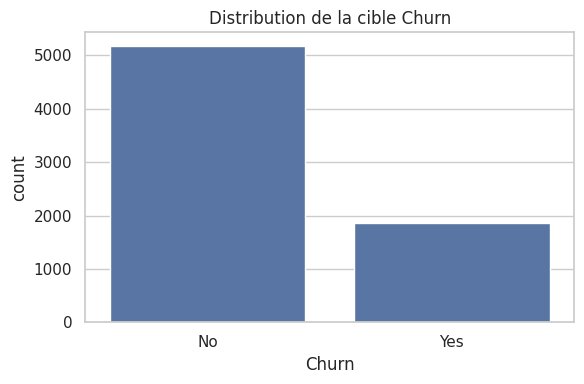

In [5]:
plt.figure(figsize=(6,4))
sns.countplot(data=df, x="Churn", order=df["Churn"].value_counts().index)
plt.title("Distribution de la cible Churn"); plt.tight_layout(); plt.show()

## 4. Nettoyage des données

`TotalCharges` peut être lue comme une chaîne de caractères et certaines lignes contiennent des chaînes vides. La conversion en numérique transforme les valeurs non convertibles en `NaN`. Ces valeurs seront imputées par le préprocesseur, ajusté uniquement sur les données d'entraînement.

Les espaces en début et fin de chaîne sont retirés, puis les doublons exacts sont supprimés s'il y en a. Dans l'exécution précédente, aucun doublon exact n'a été détecté.

**Pourquoi intégrer l'imputation au pipeline ?** L'imputation est ajustée sur chaque sous-ensemble d'entraînement, ce qui limite la fuite d'information depuis la validation ou le test.

In [6]:
df_clean = df.copy()
if "TotalCharges" in df_clean.columns:
    df_clean["TotalCharges"] = pd.to_numeric(df_clean["TotalCharges"].astype(str).str.strip().replace("", np.nan), errors="coerce")
for col in df_clean.select_dtypes(include=["object", "string"]).columns:
    df_clean[col] = df_clean[col].astype("string").str.strip()
dup_count = df_clean.duplicated().sum()
df_clean = df_clean.drop_duplicates().copy()
print("Doublons supprimés :", dup_count)
print("Dimensions après nettoyage :", df_clean.shape)
display(df_clean.isna().sum().sort_values(ascending=False).to_frame("valeurs_manquantes").head(15))

Doublons supprimés : 0
Dimensions après nettoyage : (7043, 21)


,valeurs_manquantes
TotalCharges,11
gender,0
SeniorCitizen,0
Partner,0
customerID,0
Dependents,0
tenure,0
MultipleLines,0
PhoneService,0
OnlineSecurity,0


## 5. Définir la cible et les variables explicatives

La cible est `Churn` : `No` devient `0` et `Yes` devient `1`. `X` contient les variables explicatives et `y` contient la cible.

La colonne `customerID` est retirée de `X`, car il s'agit d'un identifiant sans valeur prédictive générale à lui seul. Aucune information dérivée de `Churn` n'est ajoutée aux variables explicatives.

In [7]:
df_clean = df_clean.dropna(subset=["Churn"]).copy()
df_clean = df_clean[df_clean["Churn"].isin(["Yes", "No"])].copy()
y = df_clean["Churn"].map({"No": 0, "Yes": 1}).astype(int)
X = df_clean.drop(columns=["Churn", "customerID"], errors="ignore")
print("X :", X.shape, " y :", y.shape)
display(y.value_counts().rename(index={0:"No churn",1:"Churn"}).to_frame("effectif"))

X : (7043, 19)  y : (7043,)


,effectif
Churn,
No churn,5174
Churn,1869


## 6. Séparer les données en entraînement et test

Le jeu de test représente 20 % des observations ; les 80 % restants servent à la sélection et à l'entraînement. `stratify=y` conserve approximativement la proportion de clients churn et non-churn dans les deux ensembles.

**Règle essentielle :** le jeu de test ne sert ni à choisir les hyperparamètres ni à choisir le seuil. Il est réservé à l'évaluation finale sur des données non vues.

In [8]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)
print("Train :", X_train.shape, "Test :", X_test.shape)
print("Taux de churn train :", round(100*y_train.mean(),2), "%")
print("Taux de churn test :", round(100*y_test.mean(),2), "%")

Train : (5634, 19) Test : (1409, 19)
Taux de churn train : 26.54 %
Taux de churn test : 26.54 %


## 7. Prétraitement des variables

Le `ColumnTransformer` applique un traitement adapté à chaque type de variable :

- **Variables numériques :** imputation des valeurs manquantes par la médiane.
- **Variables catégorielles :** imputation par la modalité la plus fréquente, puis One-Hot Encoding.
- `handle_unknown="ignore"` permet de traiter les catégories nouvelles lors de la prédiction.

Le prétraitement est intégré au pipeline. À chaque pli de validation croisée, l'imputation et l'encodage sont ajustés uniquement sur le pli d'entraînement, ce qui limite la fuite de données (*data leakage*).

La standardisation n'est pas nécessaire pour ces modèles d'arbres.

In [9]:
numeric_features = X_train.select_dtypes(include=["number", "bool"]).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=["number", "bool"]).columns.tolist()
preprocessor = ColumnTransformer(transformers=[
    ("num", SimpleImputer(strategy="median"), numeric_features),
    ("cat", Pipeline(steps=[("imputer", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore"))]), categorical_features)
], remainder="drop")
print("Numériques :", numeric_features)
print("Catégorielles :", categorical_features)

Numériques : ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Catégorielles : ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


## 8. Optimisation de Random Forest par validation croisée

**Random Forest** entraîne plusieurs arbres de décision et agrège leurs prédictions, ce qui limite la dépendance à un arbre isolé.

`StratifiedKFold` utilise cinq plis en conservant la proportion des classes. `RandomizedSearchCV` teste 12 combinaisons d'hyperparamètres et retient celle dont l'**Average Precision** moyenne est la plus élevée.

L'Average Precision résume la courbe Precision-Recall et convient notamment lorsque la classe positive (`Churn = Yes`) est minoritaire. Les paramètres explorés contrôlent le nombre d'arbres, leur profondeur, la taille minimale des feuilles, les variables examinées à chaque séparation et la pondération des classes.

In [10]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

rf_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1))
])
rf_params = {
    "classifier__n_estimators": [250, 400, 600],
    "classifier__max_depth": [None, 10, 15, 20],
    "classifier__min_samples_leaf": [1, 2, 4],
    "classifier__max_features": ["sqrt", 0.8],
    "classifier__class_weight": ["balanced", "balanced_subsample"]
}
rf_search = RandomizedSearchCV(
    rf_pipeline, rf_params, n_iter=12, scoring="average_precision",
    cv=cv, random_state=RANDOM_STATE, n_jobs=-1, refit=True,
    verbose=1, return_train_score=True
)
rf_search.fit(X_train, y_train)
best_rf = rf_search.best_estimator_
print("Random Forest — Average Precision CV moyen :", round(rf_search.best_score_, 4))
display(pd.Series(rf_search.best_params_, name="valeur").to_frame())

Fitting 5 folds for each of 12 candidates, totalling 60 fits
Random Forest — Average Precision CV moyen : 0.6583


,valeur
classifier__n_estimators,400
classifier__min_samples_leaf,4
classifier__max_features,sqrt
classifier__max_depth,10
classifier__class_weight,balanced_subsample


## 9. Optimisation de XGBoost

**XGBoost** construit des arbres successifs pour améliorer les prédictions précédentes. Les performances sont évaluées par validation croisée.

La recherche explore notamment le nombre d'arbres (`n_estimators`), la profondeur (`max_depth`), le taux d'apprentissage (`learning_rate`), les proportions de lignes et de colonnes utilisées (`subsample`, `colsample_bytree`) et les paramètres de régularisation.

`scale_pos_weight` est initialisé à partir du rapport entre les clients non-churn et churn dans le train. Cette valeur tient compte du déséquilibre des classes, sans garantir un optimum.

In [11]:
try:
    from xgboost import XGBClassifier
except ImportError as exc:
    raise ImportError("Installe XGBoost avec %pip install xgboost, puis relance les cellules.") from exc

neg, pos = int((y_train == 0).sum()), int((y_train == 1).sum())
scale_pos_weight = neg / max(pos, 1)

xgb_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", XGBClassifier(
        objective="binary:logistic", eval_metric="logloss",
        scale_pos_weight=scale_pos_weight, random_state=RANDOM_STATE, n_jobs=1
    ))
])
xgb_params = {
    "classifier__n_estimators": [200, 300, 450, 600],
    "classifier__max_depth": [3, 4, 5],
    "classifier__learning_rate": [0.03, 0.05, 0.08, 0.1],
    "classifier__subsample": [0.75, 0.85, 1.0],
    "classifier__colsample_bytree": [0.75, 0.85, 1.0],
    "classifier__min_child_weight": [1, 3, 5],
    "classifier__reg_lambda": [1, 3, 5]
}
xgb_search = RandomizedSearchCV(
    xgb_pipeline, xgb_params, n_iter=12, scoring="average_precision",
    cv=cv, random_state=RANDOM_STATE, n_jobs=-1, refit=True,
    verbose=1, return_train_score=True
)
xgb_search.fit(X_train, y_train)
best_xgb = xgb_search.best_estimator_
print("XGBoost — Average Precision CV moyen :", round(xgb_search.best_score_, 4))
display(pd.Series(xgb_search.best_params_, name="valeur").to_frame())

Fitting 5 folds for each of 12 candidates, totalling 60 fits
XGBoost — Average Precision CV moyen : 0.6652


,valeur
classifier__subsample,0.75
classifier__reg_lambda,1.00
classifier__n_estimators,450.00
classifier__min_child_weight,1.00
classifier__max_depth,3.00
classifier__learning_rate,0.05
classifier__colsample_bytree,0.85


## 10. Lire les scores de validation croisée

Le tableau présente l'Average Precision moyen et son écart-type pour la meilleure configuration trouvée. L'écart-type mesure la variation du score entre les plis.

**Nuance méthodologique :** le meilleur score de `RandomizedSearchCV` peut être optimiste, car il sert à sélectionner la meilleure configuration parmi plusieurs. L'évaluation finale sur le jeu de test indépendant reste la mesure de référence.

In [12]:
cv_summary = pd.DataFrame([
    {"Modèle": "Random Forest",
     "Average Precision CV moyen": rf_search.best_score_,
     "Écart-type CV": rf_search.cv_results_["std_test_score"][rf_search.best_index_]},
    {"Modèle": "XGBoost",
     "Average Precision CV moyen": xgb_search.best_score_,
     "Écart-type CV": xgb_search.cv_results_["std_test_score"][xgb_search.best_index_]}
]).set_index("Modèle")
display(cv_summary.round(4))

,Average Precision CV moyen,Écart-type CV
Modèle,,
Random Forest,0.6583,0.0188
XGBoost,0.6652,0.0196


## 11. Choisir le seuil de décision

Le classifieur renvoie une probabilité de churn. Le seuil transforme cette probabilité en décision : au-dessus ou au niveau du seuil, le client est classé « churn ».

Le seuil par défaut est `0.5`, mais un autre seuil peut mieux correspondre aux objectifs de fidélisation. Un faux négatif correspond à un client churn manqué ; un faux positif correspond à un client signalé à tort.

Le **F2-score** donne davantage de poids au recall qu'à la precision. Le seuil est choisi à partir de probabilités hors pli, sans utiliser le jeu de test.

Pour limiter les biais de sélection, les hyperparamètres sont également sélectionnés à l'intérieur de chaque pli extérieur. La validation croisée imbriquée (*nested cross-validation*) utilisée ci-dessous produit les probabilités servant au choix du seuil, au prix d'un temps de calcul plus élevé.

In [13]:
def choose_threshold_f2(y_true, proba):
    """Choisit le seuil qui maximise le F2-score sur des probabilités de validation."""
    precision, recall, thresholds = precision_recall_curve(y_true, proba)
    # precision et recall ont un élément de plus que thresholds.
    p, r = precision[:-1], recall[:-1]
    f2 = (5 * p * r) / (4 * p + r + 1e-12)
    idx = int(np.nanargmax(f2))
    return float(thresholds[idx]), float(f2[idx])


def nested_oof_probabilities(X, y, base_pipeline, param_distributions,
                             outer_splits=5, inner_splits=3, n_iter=8,
                             random_state=42, model_name="Modèle"):
    """
    Pour chaque pli extérieur, optimise les hyperparamètres uniquement sur le
    train extérieur, puis prédit le pli extérieur jamais vu. Cela produit des
    probabilités hors pli moins biaisées pour choisir le seuil.
    """
    outer_cv = StratifiedKFold(
        n_splits=outer_splits, shuffle=True, random_state=random_state
    )
    oof_probabilities = np.zeros(len(y), dtype=float)
    fold_scores = []

    for fold, (train_idx, valid_idx) in enumerate(outer_cv.split(X, y), start=1):
        X_outer_train = X.iloc[train_idx]
        y_outer_train = y.iloc[train_idx]
        X_outer_valid = X.iloc[valid_idx]
        y_outer_valid = y.iloc[valid_idx]

        inner_cv = StratifiedKFold(
            n_splits=inner_splits, shuffle=True, random_state=random_state + fold
        )
        inner_search = RandomizedSearchCV(
            estimator=clone(base_pipeline),
            param_distributions=param_distributions,
            n_iter=n_iter,
            scoring="average_precision",
            cv=inner_cv,
            random_state=random_state + fold,
            n_jobs=-1,
            refit=True,
            verbose=0
        )
        inner_search.fit(X_outer_train, y_outer_train)
        oof_probabilities[valid_idx] = inner_search.predict_proba(X_outer_valid)[:, 1]
        fold_ap = average_precision_score(y_outer_valid, oof_probabilities[valid_idx])
        fold_scores.append(fold_ap)
        print(f"{model_name} — pli extérieur {fold}/{outer_splits} : AP = {fold_ap:.4f}")

    return oof_probabilities, np.asarray(fold_scores)


# Validation croisée imbriquée pour le choix du seuil.
# 5 plis extérieurs × 3 plis intérieurs × 8 configurations par pli et par modèle.
# Cette procédure est plus rigoureuse, mais plus coûteuse que la validation simple.
rf_oof, rf_nested_ap = nested_oof_probabilities(
    X_train, y_train, rf_pipeline, rf_params,
    outer_splits=5, inner_splits=3, n_iter=8,
    random_state=RANDOM_STATE, model_name="Random Forest"
)
xgb_oof, xgb_nested_ap = nested_oof_probabilities(
    X_train, y_train, xgb_pipeline, xgb_params,
    outer_splits=5, inner_splits=3, n_iter=8,
    random_state=RANDOM_STATE + 100, model_name="XGBoost"
)

rf_threshold, rf_oof_f2 = choose_threshold_f2(y_train, rf_oof)
xgb_threshold, xgb_oof_f2 = choose_threshold_f2(y_train, xgb_oof)

threshold_summary = pd.DataFrame([
    {
        "Modèle": "Random Forest",
        "Seuil F2 OOF": rf_threshold,
        "F2 OOF": rf_oof_f2,
        "Average Precision nested CV": rf_nested_ap.mean(),
        "Écart-type AP nested CV": rf_nested_ap.std(ddof=1)
    },
    {
        "Modèle": "XGBoost",
        "Seuil F2 OOF": xgb_threshold,
        "F2 OOF": xgb_oof_f2,
        "Average Precision nested CV": xgb_nested_ap.mean(),
        "Écart-type AP nested CV": xgb_nested_ap.std(ddof=1)
    }
]).set_index("Modèle")

display(threshold_summary.round(4))

Random Forest — pli extérieur 1/5 : AP = 0.6316
Random Forest — pli extérieur 2/5 : AP = 0.6376
Random Forest — pli extérieur 3/5 : AP = 0.6822
Random Forest — pli extérieur 4/5 : AP = 0.6519
Random Forest — pli extérieur 5/5 : AP = 0.6659
XGBoost — pli extérieur 1/5 : AP = 0.6600
XGBoost — pli extérieur 2/5 : AP = 0.6450
XGBoost — pli extérieur 3/5 : AP = 0.7213
XGBoost — pli extérieur 4/5 : AP = 0.6566
XGBoost — pli extérieur 5/5 : AP = 0.6513


,Seuil F2 OOF,F2 OOF,Average Precision nested CV,Écart-type AP nested CV
Modèle,,,,
Random Forest,0.3297,0.7448,0.6538,0.0207
XGBoost,0.3182,0.7494,0.6668,0.0310


## 12. Évaluation finale sur le jeu de test indépendant

Après la sélection des hyperparamètres sur le train et du seuil à partir de prédictions hors pli, chaque pipeline est réentraîné sur tout le jeu d'entraînement. L'évaluation finale est ensuite réalisée sur le jeu de test, qui n'a participé à aucune de ces décisions.

Les résultats sont comparés avec le seuil standard de `0.5` et le seuil choisi par F2. Une légère différence de calibration est possible, car le seuil est choisi à partir de modèles entraînés sur des sous-ensembles du train, tandis que le modèle final est réentraîné sur tout le train.

In [14]:
best_rf.fit(X_train, y_train)
best_xgb.fit(X_train, y_train)

rf_proba = best_rf.predict_proba(X_test)[:, 1]
xgb_proba = best_xgb.predict_proba(X_test)[:, 1]

predictions = {
    ("Random Forest", "0.50"): (rf_proba >= 0.5).astype(int),
    ("Random Forest", f"{rf_threshold:.3f} (F2 OOF)"): (rf_proba >= rf_threshold).astype(int),
    ("XGBoost", "0.50"): (xgb_proba >= 0.5).astype(int),
    ("XGBoost", f"{xgb_threshold:.3f} (F2 OOF)"): (xgb_proba >= xgb_threshold).astype(int)
}

def metric_row(model, threshold, y_true, y_pred, proba):
    return {
        "Modèle": model, "Seuil": threshold,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision_Churn": precision_score(y_true, y_pred, zero_division=0),
        "Recall_Churn": recall_score(y_true, y_pred, zero_division=0),
        "F1_Churn": f1_score(y_true, y_pred, zero_division=0),
        "F2_Churn": fbeta_score(y_true, y_pred, beta=2, zero_division=0),
        "ROC_AUC": roc_auc_score(y_true, proba),
        "Average_Precision": average_precision_score(y_true, proba)
    }

test_rows = []
for (model, threshold), pred in predictions.items():
    proba = rf_proba if model == "Random Forest" else xgb_proba
    test_rows.append(metric_row(model, threshold, y_test, pred, proba))

test_results = pd.DataFrame(test_rows)
display(test_results.set_index(["Modèle", "Seuil"]).round(4))

Accuracy  Precision_Churn  Recall_Churn  \
Modèle        Seuil                                                     
Random Forest 0.50              0.7672           0.5451        0.7433   
              0.330 (F2 OOF)    0.7040           0.4687        0.8610   
XGBoost       0.50              0.7480           0.5169        0.7754   
              0.318 (F2 OOF)    0.6899           0.4564        0.8824   

                              F1_Churn  F2_Churn  ROC_AUC  Average_Precision  
Modèle        Seuil                                                           
Random Forest 0.50              0.6290    0.6929   0.8423             0.6512  
              0.330 (F2 OOF)    0.6070    0.7375   0.8423             0.6512  
XGBoost       0.50              0.6203    0.7049   0.8423             0.6647  
              0.318 (F2 OOF)    0.6016    0.7436   0.8423             0.6647

## 13. Matrices de confusion au seuil retenu

La matrice de confusion compare les prédictions aux classes réelles :

- **Vrais négatifs (TN) :** clients non-churn correctement classés.
- **Faux positifs (FP) :** clients non-churn signalés comme churn.
- **Faux négatifs (FN) :** clients churn manqués.
- **Vrais positifs (TP) :** clients churn correctement détectés.

Réduire les faux négatifs peut être prioritaire pour une campagne de fidélisation. Un seuil plus bas augmente souvent les faux positifs et le nombre de clients à contacter. Le choix dépend des coûts et de la capacité de traitement.

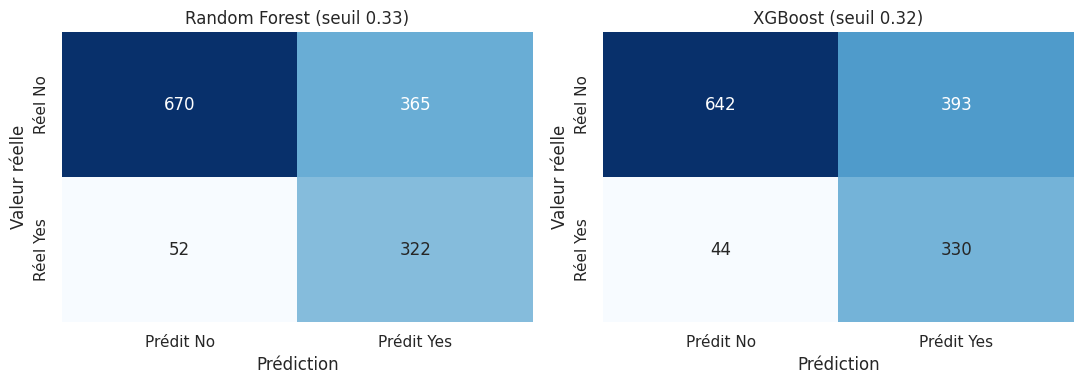

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, name, pred in [
    (axes[0], f"Random Forest (seuil {rf_threshold:.2f})",
     (rf_proba >= rf_threshold).astype(int)),
    (axes[1], f"XGBoost (seuil {xgb_threshold:.2f})",
     (xgb_proba >= xgb_threshold).astype(int))
]:
    cm = confusion_matrix(y_test, pred, labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Prédit No", "Prédit Yes"],
                yticklabels=["Réel No", "Réel Yes"])
    ax.set_title(name)
    ax.set_xlabel("Prédiction")
    ax.set_ylabel("Valeur réelle")
plt.tight_layout()
plt.show()

## 14. Courbes ROC et Precision-Recall

Les courbes sont calculées à partir des probabilités prédites, et non uniquement des décisions à un seuil donné.

- **ROC-AUC :** mesure la capacité de classement sur différents seuils.
- **Average Precision :** résume la courbe Precision-Recall et est informative lorsque la classe positive est minoritaire.

Ces métriques évaluent des aspects différents et ne déterminent pas seules le seuil métier optimal.

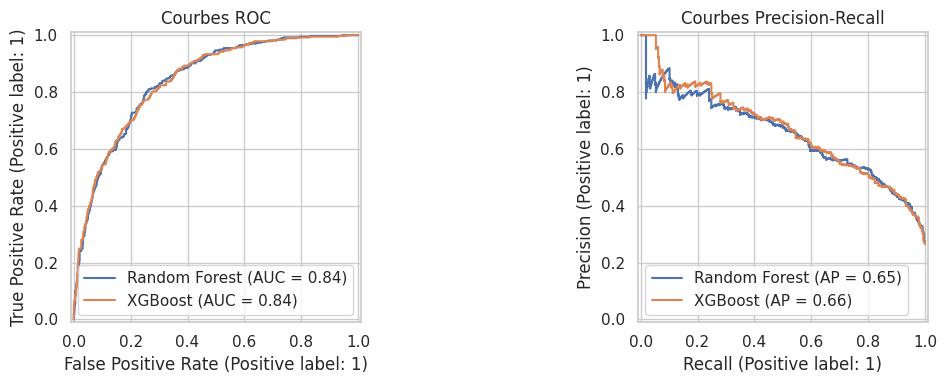

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
RocCurveDisplay.from_predictions(y_test, rf_proba, name="Random Forest", ax=axes[0])
RocCurveDisplay.from_predictions(y_test, xgb_proba, name="XGBoost", ax=axes[0])
axes[0].set_title("Courbes ROC")
PrecisionRecallDisplay.from_predictions(y_test, rf_proba, name="Random Forest", ax=axes[1])
PrecisionRecallDisplay.from_predictions(y_test, xgb_proba, name="XGBoost", ax=axes[1])
axes[1].set_title("Courbes Precision-Recall")
plt.tight_layout()
plt.show()

## 15. Importance des variables — Random Forest

L'importance native des arbres indique les variables qui contribuent le plus aux décisions du modèle. Après One-Hot Encoding, une variable catégorielle peut apparaître sous plusieurs colonnes.

**Limite :** une importance élevée ne prouve pas un lien de causalité avec la résiliation. Des variables corrélées peuvent partager leur importance. Une analyse par permutation ou SHAP peut compléter cette interprétation.

,importance
cat__Contract_Month-to-month,0.131574
num__tenure,0.123073
num__TotalCharges,0.097939
num__MonthlyCharges,0.069352
cat__Contract_Two year,0.067101
cat__OnlineSecurity_No,0.063027
cat__TechSupport_No,0.052042
cat__InternetService_Fiber optic,0.048813
cat__PaymentMethod_Electronic check,0.034143
cat__Contract_One year,0.019879


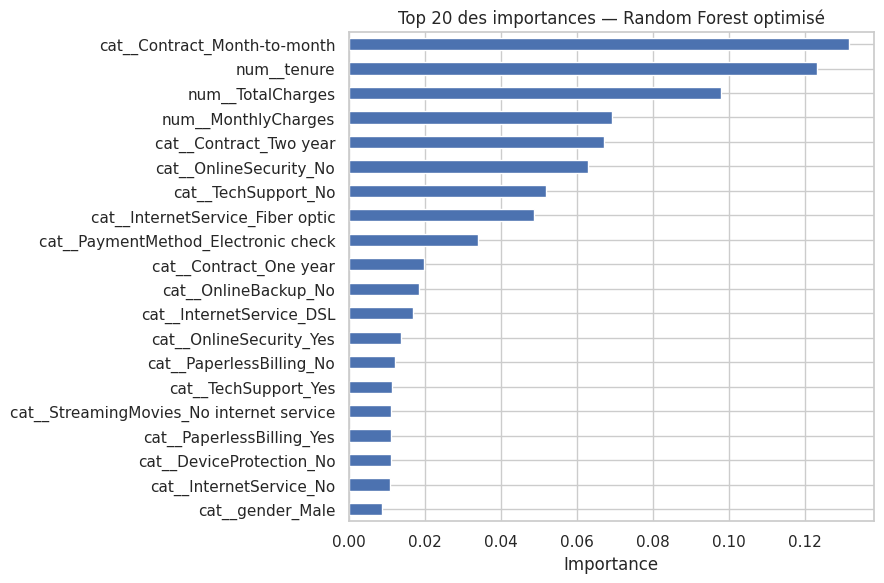

In [17]:
feature_names = best_rf.named_steps["preprocessor"].get_feature_names_out()
importances = pd.Series(
    best_rf.named_steps["classifier"].feature_importances_,
    index=feature_names
).sort_values(ascending=False).head(20)
display(importances.to_frame("importance"))
plt.figure(figsize=(9, 6))
importances.sort_values().plot(kind="barh")
plt.title("Top 20 des importances — Random Forest optimisé")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

## 16. Discussion des résultats

Après l'exécution complète du notebook, actualiser l'interprétation à partir des nouveaux tableaux. Les anciennes sorties peuvent correspondre à une procédure différente de sélection du seuil et ne doivent pas être présentées comme les résultats définitifs de cette version.

### Interprétation des métriques
- **Accuracy :** proportion de prédictions correctes ; peut être trompeuse si les classes sont déséquilibrées.
- **Precision churn :** proportion de vrais churners parmi les clients signalés comme churn.
- **Recall churn :** proportion de churners réellement détectés.
- **F1-score :** équilibre entre precision et recall.
- **F2-score :** donne plus de poids au recall.
- **ROC-AUC :** capacité de classement sur plusieurs seuils.
- **Average Precision :** résumé de la courbe Precision-Recall.

### Questions d'analyse
1. Quel modèle obtient la meilleure Average Precision en validation croisée imbriquée ?
2. L'écart-type entre les plis est-il faible ou important ?
3. Comment le seuil optimisé modifie-t-il le recall, la precision et le nombre de faux positifs ?
4. Quel compromis conviendrait à une campagne de fidélisation ?
5. Les résultats de validation croisée sont-ils cohérents avec ceux du jeu de test ?

### Trame de rédaction à compléter

> La validation croisée imbriquée à cinq plis donne une Average Precision moyenne de **[valeur]** pour Random Forest et de **[valeur]** pour XGBoost. Les seuils choisis sur les prédictions hors pli du jeu d'entraînement sont **[valeur]** et **[valeur]**. Sur le jeu de test indépendant, **[modèle]** obtient un recall de **[valeur]** et une precision de **[valeur]** pour la classe churn. Le choix final dépend du coût des résiliations manquées et des campagnes envoyées à tort.

### Limites
- La recherche aléatoire explore un nombre limité de configurations.
- La validation croisée imbriquée augmente le temps de calcul.
- Le seuil maximisant F2 est un compromis statistique, pas un optimum financier démontré.
- Une validation temporelle serait pertinente si les dates d'observation étaient disponibles.
- Les performances peuvent évoluer selon la période et la population.

## 17. Enregistrer les modèles et les résultats

Les pipelines sauvegardés incluent le prétraitement et le modèle. Les métriques, les seuils et les scores de validation croisée sont également enregistrés pour faciliter la reproductibilité.

Le dossier `outputs/` est créé dans le répertoire courant. Les fichiers `.joblib` sont facultatifs sur GitHub et peuvent être volumineux ; le notebook et le code source restent les éléments principaux.

In [18]:
import joblib
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

joblib.dump(best_rf, OUTPUT_DIR / "random_forest_churn_tuned.joblib")
joblib.dump(best_xgb, OUTPUT_DIR / "xgboost_churn_tuned.joblib")
test_results.to_csv(OUTPUT_DIR / "test_model_comparison.csv", index=False)
cv_summary.to_csv(OUTPUT_DIR / "cross_validation_summary.csv")
threshold_summary.to_csv(OUTPUT_DIR / "selected_thresholds.csv")
joblib.dump({
    "random_forest_threshold_f2_oof": float(rf_threshold),
    "xgboost_threshold_f2_oof": float(xgb_threshold),
    "threshold_selection": "F2 maximisé sur prédictions out-of-fold du train",
    "random_state": RANDOM_STATE
}, OUTPUT_DIR / "decision_thresholds.joblib")
print("Fichiers enregistrés dans :", OUTPUT_DIR.resolve())

Fichiers enregistrés dans : /kaggle/working/outputs


## 18. Exemple de prédiction sur quelques clients

Le modèle renvoie une probabilité comprise entre 0 et 1. Le seuil sélectionné transforme cette probabilité en classe prédite. Une probabilité de `0.70` représente un score de risque estimé, pas une certitude.

L'exemple utilise quelques lignes du jeu de test. En utilisation réelle, les mêmes variables explicatives et types de données sont requis, sans la colonne `Churn`.

In [19]:
sample = X_test.head(5).copy()
sample["RF_probability_churn"] = best_rf.predict_proba(X_test.head(5))[:, 1]
sample["RF_prediction_at_tuned_threshold"] = (
    sample["RF_probability_churn"] >= rf_threshold
).astype(int)
sample["XGB_probability_churn"] = best_xgb.predict_proba(X_test.head(5))[:, 1]
sample["XGB_prediction_at_tuned_threshold"] = (
    sample["XGB_probability_churn"] >= xgb_threshold
).astype(int)
display(sample)

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,RF_probability_churn,RF_prediction_at_tuned_threshold,XGB_probability_churn,XGB_prediction_at_tuned_threshold
437,Male,0,Yes,Yes,72,Yes,Yes,Fiber optic,Yes,Yes,Yes,Yes,Yes,Yes,Two year,Yes,Credit card (automatic),114.05,8468.20,0.031110,0,0.013642,0
2280,Female,1,No,No,8,Yes,Yes,Fiber optic,No,No,No,Yes,Yes,Yes,Month-to-month,Yes,Credit card (automatic),100.15,908.55,0.826153,1,0.937703,1
2235,Female,0,Yes,Yes,41,Yes,Yes,DSL,Yes,Yes,Yes,No,Yes,No,One year,Yes,Credit card (automatic),78.35,3211.20,0.106116,0,0.201551,0
4460,Male,0,Yes,No,18,Yes,No,Fiber optic,No,No,Yes,Yes,No,No,Month-to-month,No,Electronic check,78.20,1468.75,0.496230,1,0.585017,1
3761,Female,0,Yes,No,72,Yes,Yes,DSL,Yes,Yes,Yes,No,Yes,Yes,Two year,Yes,Credit card (automatic),82.65,5919.35,0.050728,0,0.014775,0
